Plots tracks of swimming cells from csv files. Used in figure 2

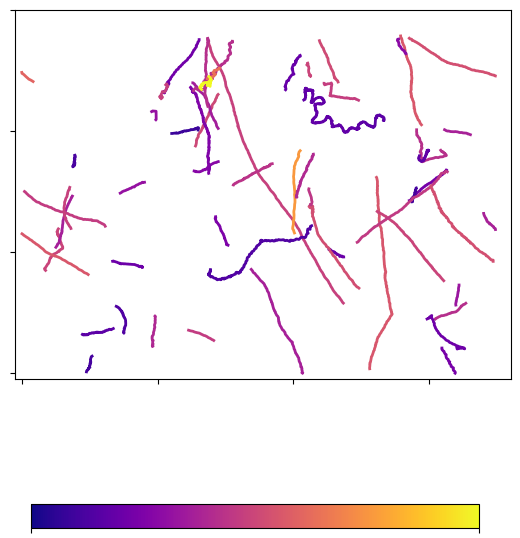

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# Load CSV files
tracks = pd.read_csv("../swimming-cells/tracks-pos.csv")

velocities = pd.read_csv("../swimming-cells/tracks-speed.csv")

# Merge velocity into track dataframe
df = tracks.merge(velocities, on="TRACK_ID")

# Normalize velocities for colormap
norm = mpl.colors.Normalize(vmin=5, vmax=30)

cmap = plt.cm.plasma
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
c = 30/110
# Plot tracks
fig, ax = plt.subplots()

for track_id, track in df.groupby("TRACK_ID"):
    v = track["VEL"].iloc[0]
    ax.plot(c*track["POSITION_X"], c*track["POSITION_Y"], color=cmap(norm(v)), linewidth=2)

# Add colorbar
cax = fig.add_axes([0.15, -0.20, 0.7, 0.05])
cbar = plt.colorbar(sm,cax=cax,
    location='bottom',
    orientation='horizontal'
)

ax.set_xlim(-5,360)
ax.set_ylim(-5,300)
ax.set_xticks([0,100,200,300],[])
ax.set_yticks([0,100,200,300],[])
plt.tick_params(axis='both', labelsize=25)
cbar.set_ticks([5, 30])
cbar.set_ticklabels(['', ''])
plt.savefig('../figure-output/tracks.pdf', dpi=600,bbox_inches='tight')
plt.show()